# Five Visualisations

## Introduction

This project demonstrates five different data visualisations
using Python, Pandas and Matplotlib.

The dataset contains product sales information,
advertising expenses and monthly sales trends.

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Consistent colour scheme
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["figure.dpi"] = 100

colors = ["#2563EB", "#0D9488", "#F59E0B",
          "#8B5CF6", "#EF4444"]

# Create output folder
os.makedirs("reports/figures", exist_ok=True)

print("Libraries imported successfully!")

Libraries imported successfully!


In [11]:
np.random.seed(42)

n = 180

df = pd.DataFrame({
    "Date": pd.date_range(
        start="2025-01-01",
        periods=n,
        freq="D"
    ),
    "Category": np.random.choice(
        ["Electronics", "Clothing", "Food", "Furniture"],
        n
    ),
    "Ad_Spend": np.random.randint(100, 1000, n)
})

# Generate sales based partly on advertising spend
category_effect = df["Category"].map({
    "Electronics": 500,
    "Clothing": 200,
    "Food": 100,
    "Furniture": 350
})

df["Sales"] = (
    500 + 2.5 * df["Ad_Spend"]
    + category_effect
    + np.random.normal(0, 200, n)
).clip(lower=100)

print(df.head())

        Date     Category  Ad_Spend        Sales
0 2025-01-01         Food       712  2431.976559
1 2025-01-02    Furniture       561  2408.864574
2 2025-01-03  Electronics       742  2607.609858
3 2025-01-04         Food       868  2505.908677
4 2025-01-05         Food       104   964.388313


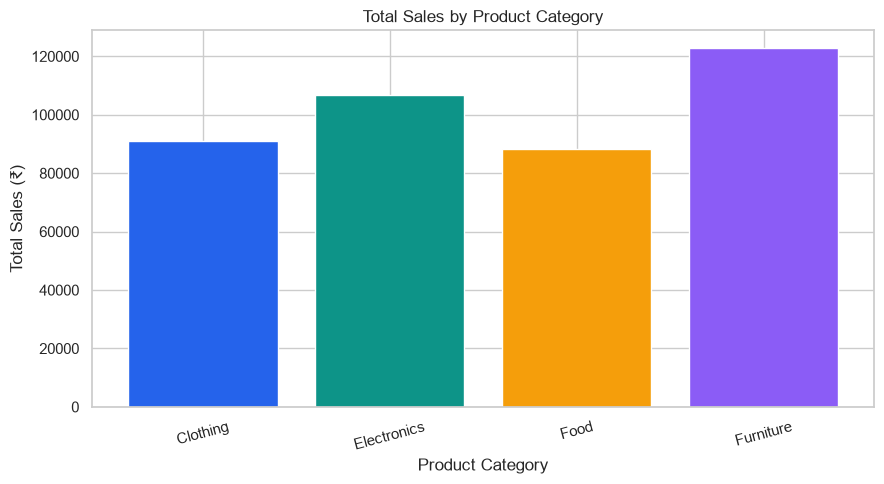

In [12]:
# Calculate sales by category
category_sales = df.groupby("Category")["Sales"].sum()

plt.figure(figsize=(9, 5))

plt.bar(
    category_sales.index,
    category_sales.values,
    color=colors
)

plt.title("Total Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales (₹)")
plt.xticks(rotation=15)

plt.tight_layout()

plt.savefig(
    "reports/figures/01_bar_chart.png",
    dpi=300
)

plt.show()

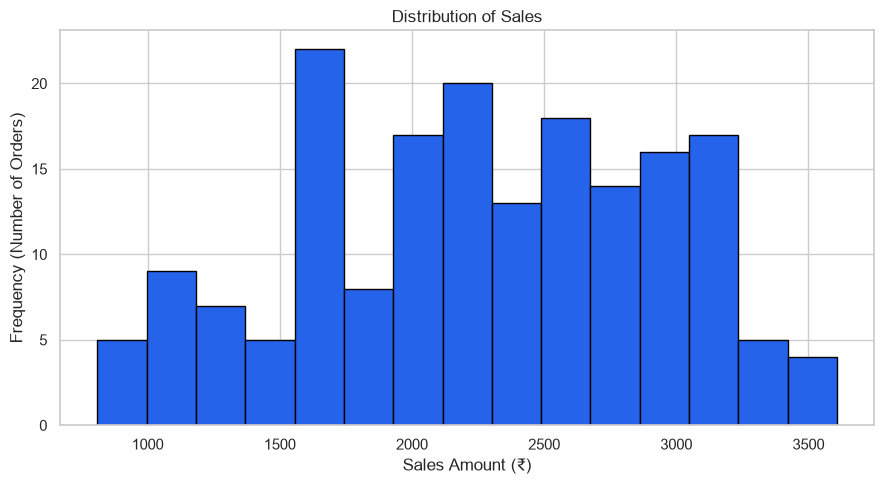

In [13]:
plt.figure(figsize=(9, 5))

plt.hist(
    df["Sales"],
    bins=15,
    color="#2563EB",
    edgecolor="black"
)

plt.title("Distribution of Sales")
plt.xlabel("Sales Amount (₹)")
plt.ylabel("Frequency (Number of Orders)")

plt.tight_layout()

plt.savefig(
    "reports/figures/02_histogram.png",
    dpi=300
)

plt.show()

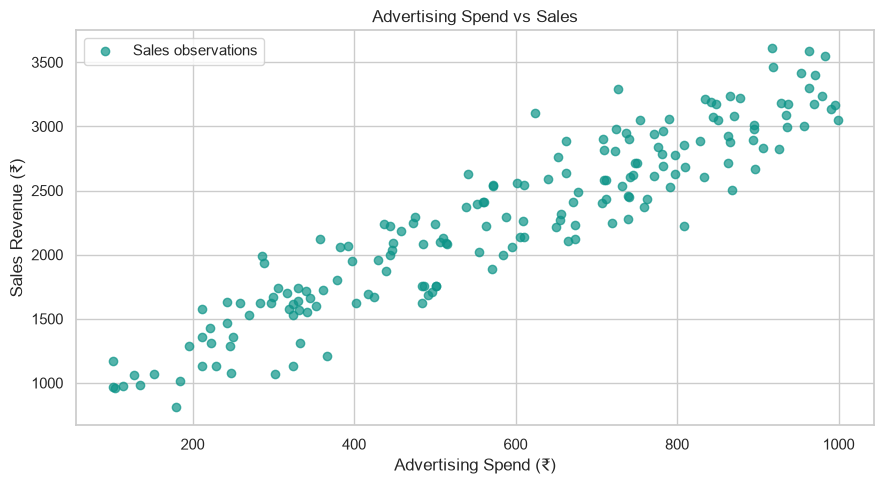

In [14]:
plt.figure(figsize=(9, 5))

plt.scatter(
    df["Ad_Spend"],
    df["Sales"],
    color="#0D9488",
    alpha=0.7,
    label="Sales observations"
)

plt.title("Advertising Spend vs Sales")
plt.xlabel("Advertising Spend (₹)")
plt.ylabel("Sales Revenue (₹)")

plt.legend()

plt.tight_layout()

plt.savefig(
    "reports/figures/03_scatter_plot.png",
    dpi=300
)

plt.show()

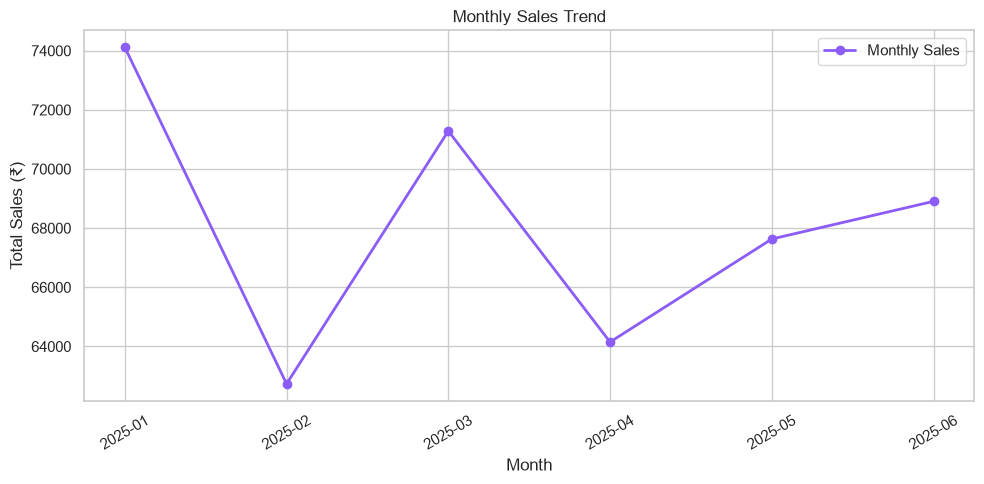

In [15]:
df["Month"] = df["Date"].dt.to_period("M")

monthly_sales = df.groupby("Month")["Sales"].sum()

plt.figure(figsize=(10, 5))

plt.plot(
    monthly_sales.index.astype(str),
    monthly_sales.values,
    marker="o",
    color="#8B5CF6",
    linewidth=2,
    label="Monthly Sales"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales (₹)")

plt.legend()

plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig(
    "reports/figures/04_line_chart.png",
    dpi=300
)

plt.show()

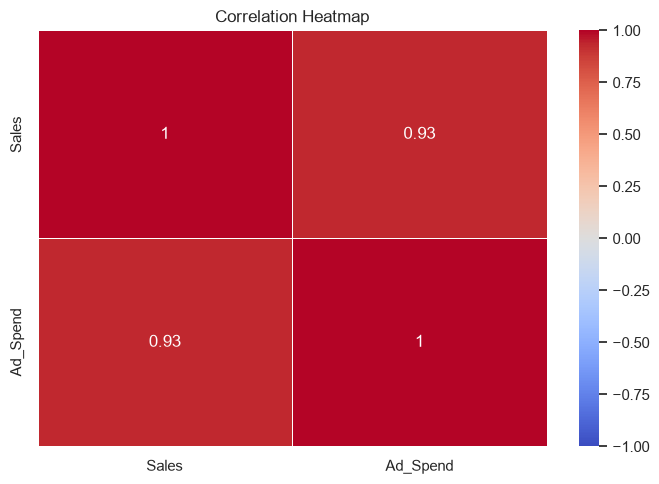

In [16]:
# Calculate correlation
correlation = df[
    ["Sales", "Ad_Spend"]
].corr()

plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap")

plt.tight_layout()

plt.savefig(
    "reports/figures/05_heatmap.png",
    dpi=300
)

plt.show()

In [17]:
figure_folder = "reports/figures"

files = os.listdir(figure_folder)

print("Saved Figures:")

for file in sorted(files):
    print(file)

print("\nTotal figures:", len(files))

Saved Figures:
01_bar_chart.png
02_histogram.png
03_scatter_plot.png
04_line_chart.png
05_heatmap.png

Total figures: 5


## Conclusion

In this project, five different visualisations were
created using Python.

1. Bar chart – Compared sales across categories.
2. Histogram – Displayed the distribution of sales.
3. Scatter plot – Examined advertising spend and sales.
4. Line chart – Showed monthly sales trends.
5. Heatmap – Displayed correlations between variables.

These visualisations help understand sales data
and communicate useful business insights.